# 02b Prep: Creating Training data for Semantic segmentation
Includes:  
- Tiling & Chipping  
- Batch & Pairing  
- Quality Check
---
For running this in Colab, use the next 2 code cells:

In [1]:
# Install geospatial libraries
%pip install -q requests geopandas pillow rasterio rioxarray geoai-py leafmap matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# load libraries
from pathlib import Path
import geoai
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import geopandas as gpd
import rasterio
from rasterio.windows import Window

In [3]:
# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Change project folder/adapt path
DATA_DIR = Path("/content/drive/MyDrive")

Mounted at /content/drive


In [4]:
# List files in the processed data directory to make sure the data is there
!ls "/content/drive/MyDrive/SDS320/01_data/processed"

mask_subset_center01.tif  ortho_subset_center01.tif


In [5]:
# raster and vector mask paths
ortho_path = "/content/drive/MyDrive/SDS320/01_data/processed/ortho_subset_center01.tif"
mask_path = "/content/drive/MyDrive/SDS320/01_data/processed/mask_subset_center01.tif"

In [6]:
# Verify raster alignment
with rasterio.open(ortho_path) as ortho:
    print("ORTHO")
    print(ortho.shape)
    print(ortho.crs)
    print(ortho.bounds)

with rasterio.open(mask_path) as mask:
    print("\nMASK")
    print(mask.shape)
    print(mask.crs)
    print(mask.bounds)

ORTHO
(6667, 6667)
EPSG:2056
BoundingBox(left=2666250.05, bottom=1210249.925, right=2666750.0749999997, top=1210749.95)

MASK
(6667, 6667)
EPSG:2056
BoundingBox(left=2666250.05, bottom=1210249.925, right=2666750.0749999997, top=1210749.95)


---
#### 3) Training Data Generation
**Tiling and Chipping:**  
According to this Docstring for the *geoai.export_geotiff_tiles function* it expects EITHER vector OR raster data for the in_class_data  
This is perfect as we already have rasterized my vector mask (also did the raster calculations, would not make much sense to already vectorize back)  

In the next step we need to define the parameters for that specific GeoAI function in order to create image tiles.

**Batch and Pair:**  
three pairing options
- single vector file covering all images  
- Multiple vector files matched by sorted order  
- Multiple vector files matched by filename   

should already be done correctly by the worksteps before...

In [7]:
# Selecting tile size and stride
### starting with a smaller/moderarte overlap of 25% before scaling up
tile_size = 512  # Size of each tile (height, width)
stride_size = 384  # Stride for sliding window (height, width)

# Define output path
output_dir = Path("/content/drive/MyDrive/SDS320/01_data/training")

In [8]:
# Generating tiles from the orthophoto and mask
## based on workflow from gitbook
if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap

tiles = geoai.export_geotiff_tiles(
    in_raster=ortho_path,
    out_folder=output_dir,
    in_class_data=mask_path,
    tile_size=tile_size,
    stride=stride_size,
    buffer_radius=0,
    create_overview=True,
    quiet=True,
)

In [9]:
geoai.view_image("output/overview.png", figsize=(18, 10))

RasterioIOError: output/overview.png: No such file or directory

In [14]:
from pathlib import Path

n_tiles = len(list(Path(output_dir).rglob("*.tif")))
print(f"Found {n_tiles} tif files")

Found 648 tif files


In [15]:
from pathlib import Path
import rasterio
import matplotlib.pyplot as plt

tile_files = sorted(Path(output_dir).rglob("*.tif"))

print(tile_files[:10])

[PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000000.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000001.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000002.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000003.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000004.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000005.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000006.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000007.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000008.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000009.tif')]


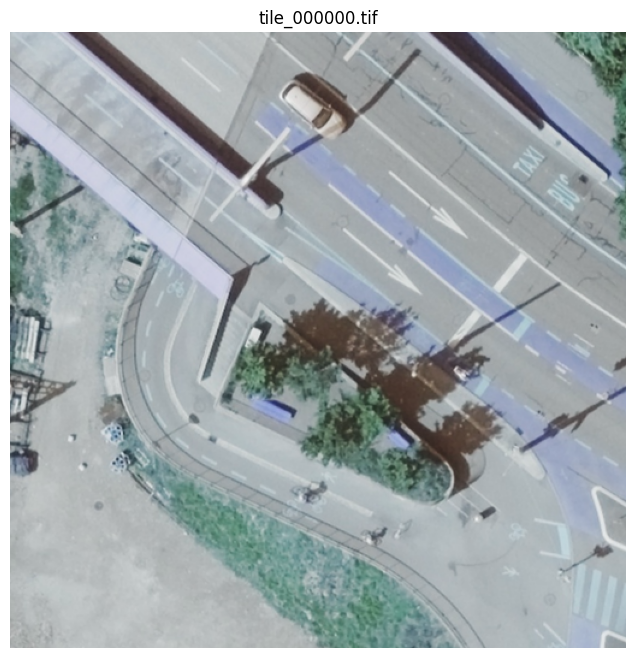

In [16]:
img_tile = tile_files[0]

with rasterio.open(img_tile) as src:
    rgb = src.read([1, 2, 3])

rgb = rgb.transpose(1, 2, 0)

plt.figure(figsize=(8,8))
plt.imshow(rgb)
plt.title(img_tile.name)
plt.axis("off")
plt.show()

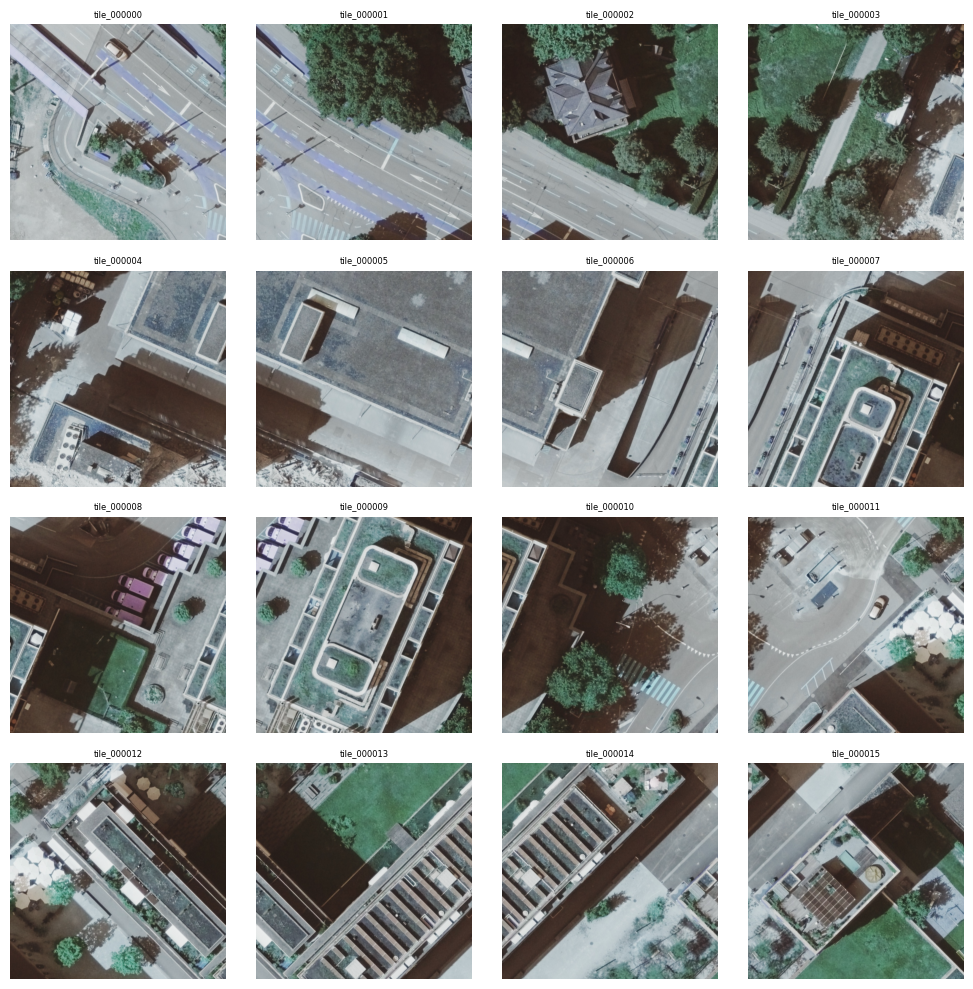

In [17]:
from pathlib import Path
import rasterio
import matplotlib.pyplot as plt

tile_paths = sorted(Path(output_dir).rglob("*.tif"))[:16]

fig, axes = plt.subplots(4, 4, figsize=(10,10))

for ax, tile in zip(axes.flatten(), tile_paths):

    with rasterio.open(tile) as src:
        rgb = src.read([1,2,3])

    rgb = rgb.transpose(1,2,0)

    ax.imshow(rgb)
    ax.set_title(tile.stem, fontsize=6)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
import rasterio
import matplotlib.pyplot as plt

with rasterio.open(image_tile) as src:
    rgb = src.read([1,2,3])

with rasterio.open(mask_tile) as src:
    mask = src.read(1)

rgb = rgb.transpose(1,2,0)

plt.figure(figsize=(8,8))
plt.imshow(rgb)
plt.imshow(mask, alpha=0.4, cmap="jet")
plt.axis("off")
plt.show()

NameError: name 'image_tile' is not defined

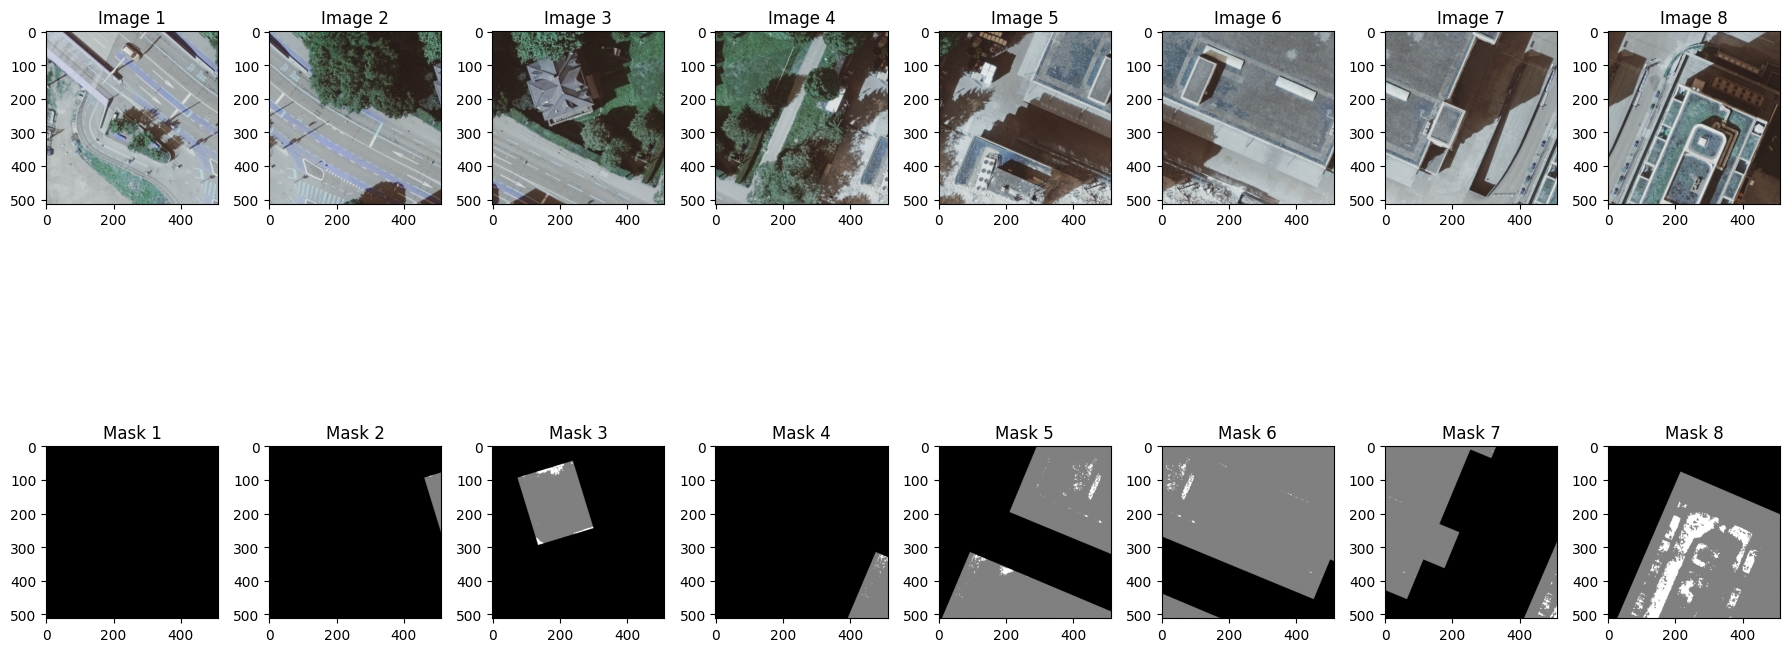

In [11]:
fig = geoai.display_training_tiles(
    output_dir=output_dir,
    num_tiles=8,
    figsize=(18, 10),
)

# verify whether all roofs are fully visible
## whether masks align with buildings
### whether enough positive samples exist
#### whether no obvious shift between imagery and labels

In [19]:
from pathlib import Path
import rasterio
import numpy as np

mask_files = sorted(Path(output_dir).glob("*mask*.tif"))

total_pixels = 0
positive_pixels = 0

for f in mask_files:
    with rasterio.open(f) as src:
        mask = src.read(1)

    total_pixels += mask.size
    positive_pixels += np.sum(mask == 1)

print(f"Positive fraction: {positive_pixels / total_pixels:.3f}")

ZeroDivisionError: division by zero

In [20]:
from pathlib import Path

for p in Path(output_dir).rglob("*"):
    print(p)

/content/drive/MyDrive/SDS320/01_data/training/images
/content/drive/MyDrive/SDS320/01_data/training/labels
/content/drive/MyDrive/SDS320/01_data/training/annotations
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000000.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000001.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000002.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000003.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000004.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000005.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000006.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000007.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000008.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000009.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_000010.tif
/content/drive/MyDrive/SDS320/01_data/training/images/tile_0000

In [21]:
from pathlib import Path

tifs = list(Path(output_dir).rglob("*.tif"))

print(f"Found {len(tifs)} tif files")
print(tifs[:10])

Found 648 tif files
[PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000000.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000001.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000002.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000003.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000004.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000005.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000006.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000007.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000008.tif'), PosixPath('/content/drive/MyDrive/SDS320/01_data/training/images/tile_000009.tif')]


In [23]:
# list all files in training data tiles directory to make sure the data is there
for p in Path(output_dir / "tiles").rglob("*"):
    print(p)

In [13]:
# Check summary statistics
# not yet adjusted for my dataset...
stats = geoai.export_geotiff_tiles_batch(
    images_folder=f"{data_dir}/images",
    masks_file=f"{data_dir}/mask1/willisau_2024_swissbuildings3D_clip.geojson",
    output_folder="output/advanced_example",
    tile_size=512,
    stride=256,
    class_value_field="class",
    buffer_radius=0.5,
    skip_empty_tiles=True,
    all_touched=True,
    max_tiles=10,
    quiet=False,
)
print(f"Generated {stats['total_tiles']} tiles with 50% overlap")

print("Images processed:", stats["processed_pairs"])
print("Total tiles generated:", stats["total_tiles"])
print("Tiles with features:", stats["tiles_with_features"])

if stats["total_tiles"] > 0:
    feature_percentage = stats["tiles_with_features"] / stats["total_tiles"] * 100
    print(f"Feature percentage: {feature_percentage:.1f}%")

NameError: name 'data_dir' is not defined